# Этап 2 Первичный анализ матчей CS2 на FACEIT
Кукин Олег АД-24

Датасет: Counter Strike 2 Win Prediction (FACEIT), Pierce Hentosh.
[Источник на Kaggle](https://www.kaggle.com/datasets/piercehentosh/counter-strike-2-win-prediction-faceit).
Цель этого этапа - проверить данные и подготовить таблицу для дальнейшего анализа.

## 1 Загрузка данных и библиотек

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

In [32]:
df = pd.read_csv("win_prediction_data_clean1.csv", sep=";")

In [33]:
df.head()

,win,map,Team_A_avg_win_percentage,Team_A_avg_KR,Team_A_avg_elo,Team_B_avg_win_percentage,Team_B_avg_KR,Team_B_avg_elo,Match ID
0,team a,de_mirage,58.864865,0.726308,1720.4,47.289216,0.792615,1536,1-051c5a18-6a99-4e5e-bef7-ed1143474b33
1,team a,de_inferno,52.341629,0.764807,1989.6,54.823232,0.762641,2073,1-8f29e3ec-f49d-4d05-8eac-98993126c405
2,team b,de_mirage,48.414652,0.733409,2565.0,62.631108,0.838246,2219,1-34674634-6bc9-45bc-b022-3f3161d5aede
3,team b,de_mirage,43.571196,0.709982,1484.4,55.513072,0.768946,1352,1-a9869c55-52a9-45a8-beb6-1fdffed4506d
4,team b,de_anubis,29.802198,0.596095,1443.4,45.317460,0.690571,1632,1-f4f59665-2fb0-46e9-a617-7003bb038bc2


## 2 Общая информация

In [34]:
df.shape

(9651, 9)

In [35]:
df.columns

Index(['win', 'map', 'Team_A_avg_win_percentage', 'Team_A_avg_KR',
       'Team_A_avg_elo', 'Team_B_avg_win_percentage', 'Team_B_avg_KR',
       'Team_B_avg_elo', 'Match ID'],
      dtype='object')

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9651 entries, 0 to 9650
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   win                        9651 non-null   object 
 1   map                        9651 non-null   object 
 2   Team_A_avg_win_percentage  9651 non-null   float64
 3   Team_A_avg_KR              9651 non-null   float64
 4   Team_A_avg_elo             9651 non-null   float64
 5   Team_B_avg_win_percentage  9651 non-null   float64
 6   Team_B_avg_KR              9651 non-null   float64
 7   Team_B_avg_elo             9651 non-null   int64  
 8   Match ID                   9651 non-null   object 
dtypes: float64(5), int64(1), object(3)
memory usage: 678.7+ KB


In [37]:
df.describe().round(2)

,Team_A_avg_win_percentage,Team_A_avg_KR,Team_A_avg_elo,Team_B_avg_win_percentage,Team_B_avg_KR,Team_B_avg_elo
count,9651.00,9651.00,9651.00,9651.00,9651.00,9651.00
mean,50.54,0.73,1756.90,50.58,0.73,1648.39
std,11.94,0.05,411.98,11.58,0.05,447.71
min,0.00,0.39,821.00,0.00,0.29,801.00
25%,44.98,0.70,1456.10,45.04,0.70,1310.00
50%,51.14,0.73,1702.20,50.97,0.73,1606.00
75%,56.99,0.76,2007.30,56.79,0.76,1969.50
max,100.00,0.95,3803.80,100.00,1.06,3989.00


В таблице 9 651 запись и 9 столбцов: шесть числовых и три текстовых.

## 3 Пропущенные значения

In [38]:
df.isna().sum()

,0
win,0
map,0
Team_A_avg_win_percentage,0
Team_A_avg_KR,0
Team_A_avg_elo,0
Team_B_avg_win_percentage,0
Team_B_avg_KR,0
Team_B_avg_elo,0
Match ID,0


In [39]:
(df.isna().mean() * 100).round(2)

,0
win,0.0
map,0.0
Team_A_avg_win_percentage,0.0
Team_A_avg_KR,0.0
Team_A_avg_elo,0.0
Team_B_avg_win_percentage,0.0
Team_B_avg_KR,0.0
Team_B_avg_elo,0.0
Match ID,0.0


## 4 Дубликаты и повторяющиеся матчи

In [40]:
df.duplicated().sum()

np.int64(0)

In [41]:
df["Match ID"].duplicated().sum()

np.int64(534)

In [42]:
df["Match ID"].nunique()

9117

In [43]:
repeated = df[df["Match ID"].duplicated(keep=False)]
repeated["Match ID"].nunique()

511

In [44]:
repeated = repeated.sort_values("Match ID")
repeated.head(4)

,win,map,Team_A_avg_win_percentage,Team_A_avg_KR,Team_A_avg_elo,Team_B_avg_win_percentage,Team_B_avg_KR,Team_B_avg_elo,Match ID
6954,team a,de_mirage,57.087879,0.736844,1980.0,48.611494,0.640117,2179,1-01e3bf44-a02a-4267-8fbb-352d00e4b4bd
1931,team a,de_mirage,56.094416,0.760160,1977.6,48.342603,0.642919,2177,1-01e3bf44-a02a-4267-8fbb-352d00e4b4bd
3918,team a,de_inferno,57.898944,0.723903,1647.2,41.962482,0.711019,1376,1-0280ae0a-a2af-4874-9912-19dfa01c4688
8519,team a,de_inferno,59.249084,0.717280,1712.0,41.308887,0.710875,1376,1-0280ae0a-a2af-4874-9912-19dfa01c4688


In [45]:
map_counts = repeated.groupby("Match ID")["map"].nunique()
win_counts = repeated.groupby("Match ID")["win"].nunique()
print("Матчи с разными картами:", (map_counts > 1).sum())
print("Матчи с разными победителями:", (win_counts > 1).sum())

Матчи с разными картами: 0
Матчи с разными победителями: 0


## 5 Уникальные значения и константные признаки

In [46]:
df.nunique()

,0
win,2
map,9
Team_A_avg_win_percentage,8690
Team_A_avg_KR,9419
Team_A_avg_elo,5523
Team_B_avg_win_percentage,8797
Team_B_avg_KR,9464
Team_B_avg_elo,1864
Match ID,9117


In [47]:
unique_counts = df.nunique()
unique_counts[unique_counts <= 1]

,0


In [48]:
df["map"].value_counts()

,count
map,
de_mirage,2643
de_anubis,1503
de_dust2,1402
de_inferno,1339
de_ancient,1320
de_nuke,712
de_vertigo,445
de_train,221
de_overpass,66


В данных девять карт: больше всего записей на Mirage (2 643), меньше всего на Overpass (66).

## 6 Баланс классов

In [49]:
df["win"].value_counts(dropna=False)

,count
win,
team b,4852
team a,4799


In [50]:
(df["win"].value_counts(normalize=True) * 100).round(2)

,proportion
win,
team b,50.27
team a,49.73


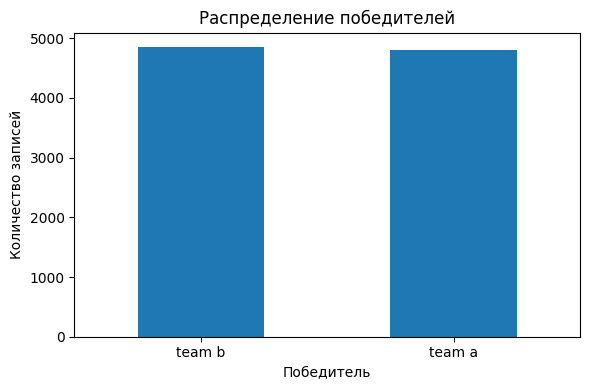

In [51]:
wins = df["win"].value_counts()
wins.plot(kind="bar", figsize=(6, 4))
plt.title("Распределение победителей")
plt.xlabel("Победитель")
plt.ylabel("Количество записей")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Победы A - 49,73%, а B - 50,27%.

## 7 Распределения числовых признаков

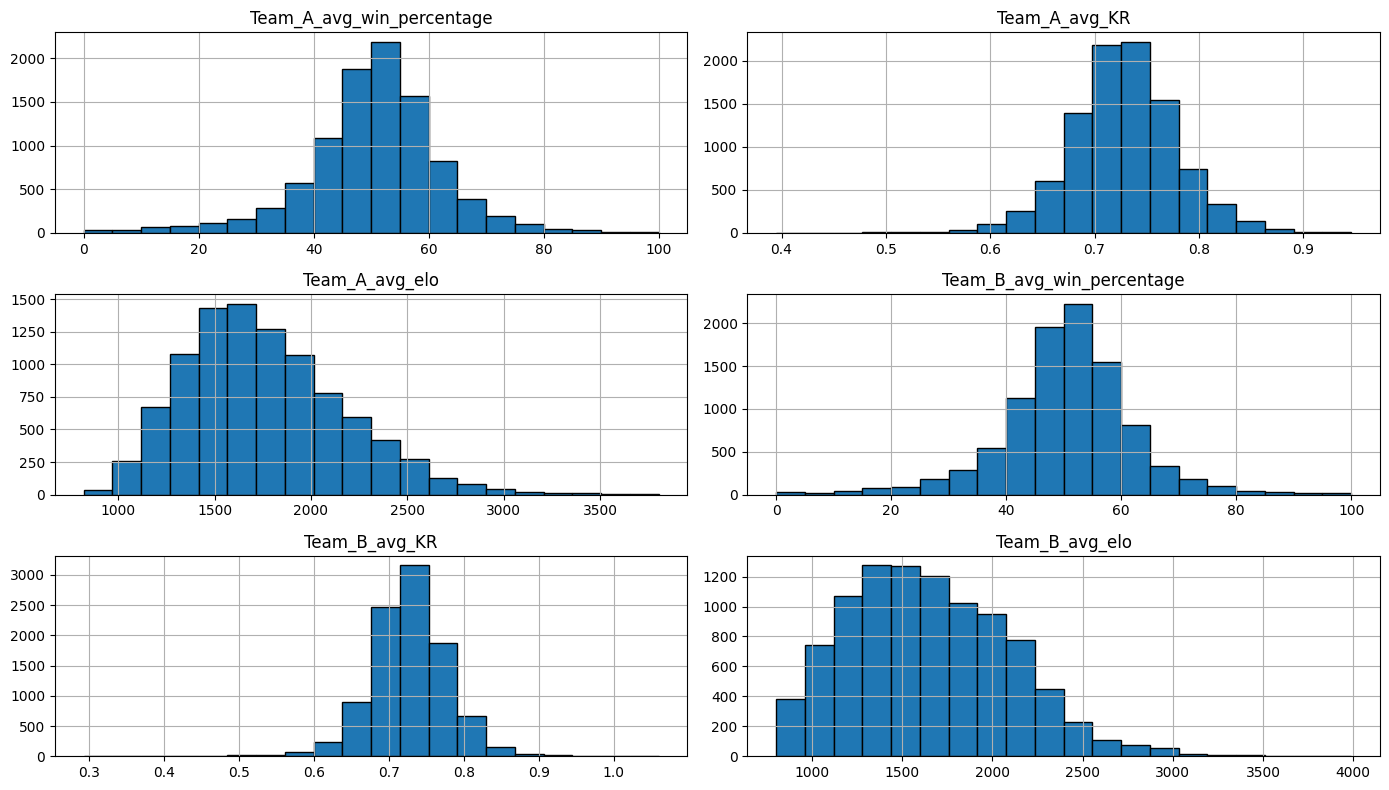

In [52]:
numeric_columns = [
    "Team_A_avg_win_percentage", "Team_A_avg_KR", "Team_A_avg_elo",
    "Team_B_avg_win_percentage", "Team_B_avg_KR", "Team_B_avg_elo"
]
features = df[numeric_columns]
features.hist(bins=20, figsize=(14, 8), edgecolor="black")
plt.tight_layout()
plt.show()

## 8 Boxplot одного признака

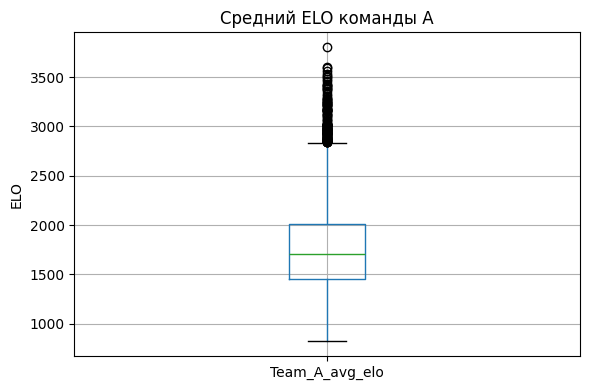

In [53]:
column = "Team_A_avg_elo"
df.boxplot(column=column, figsize=(6, 4))
plt.title("Средний ELO команды A")
plt.ylabel("ELO")
plt.tight_layout()
plt.show()

## 9 Краткий итог проверки

In [54]:
print("Количество записей:", len(df))
print("Количество столбцов:", len(df.columns))
print("Пропущенных ячеек:", df.isna().sum().sum())
print("Полных дубликатов:", df.duplicated().sum())
print("Уникальных матчей:", df["Match ID"].nunique())
print("Дополнительных записей по номеру матча:", df["Match ID"].duplicated().sum())

Количество записей: 9651
Количество столбцов: 9
Пропущенных ячеек: 0
Полных дубликатов: 0
Уникальных матчей: 9117
Дополнительных записей по номеру матча: 534


## 10 Предобработка данных

In [55]:
df_clean = df.drop_duplicates(subset="Match ID", keep="first")

In [56]:
print("Записей после выбора:", len(df_clean))
print("Исключено повторных записей:", len(df) - len(df_clean))
print("Пропущенных ячеек:", df_clean.isna().sum().sum())
print("Полных дубликатов:", df_clean.duplicated().sum())
print("Повторных номеров матчей:", df_clean["Match ID"].duplicated().sum())

Записей после выбора: 9117
Исключено повторных записей: 534
Пропущенных ячеек: 0
Полных дубликатов: 0
Повторных номеров матчей: 0


In [57]:
df_clean["win"].value_counts()

,count
win,
team b,4582
team a,4535


In [58]:
(df_clean["win"].value_counts(normalize=True) * 100).round(2)

,proportion
win,
team b,50.26
team a,49.74
